# Questão 8 — O formato da loss sob desbalanceamento de classes

## A pergunta

> *Qual loss dá mais resultado na classe minoritária a FLOPs iguais, e ela muda a geometria da
> representação oculta como Müller et al. afirmam?*

76 % das linhas do Adult são `<=50K`. A entropia cruzada trata todas as linhas igualmente, e o
modelo pode marcar 0,76 ignorando a classe minoritária. Uma família de losses tenta corrigir
isso sem custo de FLOPs: a **focal** reduz o peso dos exemplos fáceis, o **label smoothing**
suaviza os alvos e a **PolyLoss** repondera o primeiro termo da expansão da entropia cruzada.
Este notebook mede se alguma delas funciona sem aumentar o custo.

## O que a literatura afirma



| Artigo                           | O que afirma                                                                                      |
|----------------------------------|---------------------------------------------------------------------------------------------------|
| Lin et al. (focal)               | reduzir o peso dos exemplos fáceis resolve o desbalanceamento extremo (~1:1000) da detecção densa |
| Szegedy et al. (label smoothing) | suavizar os alvos regulariza e evita logits enormes                                               |
| Müller et al.                    | o smoothing aperta os clusters da penúltima camada em volta dos templates e melhora a calibração  |
| Leng et al. (Poly-1)             | ajustar o peso do termo $(1-\hat y_y)$ rende alguns décimos de ponto em vários benchmarks              |

In [1]:
import gc
import json
import pathlib
import sys
import time

ROOT = pathlib.Path.cwd()
while not (ROOT / "bert_cpu").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from bert_cpu import engine as cpu
from research.benchmark import (MLP, baseline_mlp, load_adult_cached, run_adult,
                                silhouette_score, train_val_split)

HERE = ROOT / "experiments" / "loss_imbalance"
RESULTS = HERE / "results"
FIGURES = HERE / "figures"
RESULTS.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

# Paleta e estilo das figuras
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#8a8984"
plt.style.use("default")
plt.rcParams.update({
    "font.size": 11, "axes.grid": True, "grid.color": "#e4e3df", "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 2,
    "savefig.dpi": 200, "savefig.bbox": "tight",
})

START_TIME = time.time()

## 1. O problema e o que fica fixo

Cada seed sorteia uma divisão 80/20 de `adult.data` em treino e validação e fixa a
inicialização dos pesos. O `adult.test` (16 281 linhas) só é olhado nos runs finais.

O que torna a comparação **a FLOPs iguais** é fixar todo o resto: o mesmo MLP da q05, o mesmo
Adam full-batch com lr 1e-2 e os mesmos 100 passos.

Antes de treinar, vale relembrar que para nossa base um modelo burro pode sempre responder `<=50K` e acertar 76 %, e não
encontrar nenhum `>50K`. Por isso a acurácia sozinha esconde o efeito que queremos medir.

In [2]:
train_ds, test_ds = load_adult_cached()
print(train_ds, test_ds)
for split_name, dataset in (("treino", train_ds), ("teste", test_ds)):
    print(f"{split_name:7s}: {dataset.y.size:6,d} linhas   fração >50K = {dataset.y.mean():.3f}")
print(f"\n'sempre <=50K' no teste: acurácia {1 - test_ds.y.mean():.3f}")

AdultDataset(split='train', n_features=108, n_samples=32561) AdultDataset(split='test', n_features=108, n_samples=16281)
treino : 32,561 linhas   fração >50K = 0.241
teste  : 16,281 linhas   fração >50K = 0.236

'sempre <=50K' no teste: acurácia 0.764


### O baseline, reproduzido antes de mudar qualquer coisa

O protocolo do projeto pede que o ponto de partida seja reproduzido antes de qualquer
variação. `research/benchmark.py` garante que `run_adult(baseline_mlp, seed=0)` dá a acurácia
de teste da q05, **0,8543**, com **84 227 782 200** FLOPs de treino, portanto:

In [3]:
start = time.time()
baseline = run_adult(baseline_mlp, seed=0, name="baseline (q05)")
print(f"acurácia de teste = {baseline.score:.4f}   (q05: 0.8543)")
print(f"FLOPs de treino   = {baseline.train_flops:,}   (q05: 84,227,782,200)")
print(f"tempo             = {time.time() - start:.1f} s")
del baseline
gc.collect()

acurácia de teste = 0.8543   (q05: 0.8543)
FLOPs de treino   = 84,227,782,200   (q05: 84,227,782,200)
tempo             = 11.3 s


3381

## 2. As cinco losses

**Notação.** A rede é $\mathbf a^{(0)} = \mathbf x$, $\mathbf z^{(1)} = (\mathbf W^{(1)})^\top \tilde{\mathbf x}$, $\mathbf a^{(1)} = \mathrm{ReLU}(\mathbf z^{(1)})$, $\mathbf z^{(2)} = (\mathbf W^{(2)})^\top \tilde{\mathbf a}^{(1)}$ e $\hat{\mathbf y} = \mathrm{softmax}(\mathbf z^{(2)})$, com o bias na linha 0 de cada $\mathbf W^{(\ell)}$. Para cada pessoa, $y$ é a classe verdadeira, $\mathbf y \in \{0,1\}^C$ é o rótulo one-hot e $\hat y_c$ é a probabilidade que o modelo dá à classe $c$; $\hat y_y$ é a probabilidade dada à **classe correta**. No Adult há $C = 2$ classes: `<=50K` (majoritária, 75,9%) e `>50K` (minoritária, 24,1%). As fórmulas abaixo são a loss de **uma** pessoa, $\mathcal L$; o que o treino minimiza é o custo médio sobre as $m$ pessoas do lote, $J = \frac{1}{m}\sum_{i=1}^{m} \mathcal L_i$.

| Loss | Perda por exemplo $\mathcal L$ | Hiperparâmetro | O que muda em relação à CE |
|---|---|---|---|
| CE | $-\log \hat y_y$ | — | (referência) |
| CE ponderada | $\omega_y\,(-\log \hat y_y)$ | — | pesa cada exemplo pela **classe** |
| Focal (Lin et al.) | $-(1-\hat y_y)^{\gamma}\log \hat y_y$ | $\gamma$ | pesa cada exemplo pela **dificuldade** |
| Label smoothing (Szegedy et al.) | $-\sum_c y^{\text{LS}}_c \log \hat y_c$ | $\varepsilon$ | troca o **alvo** por um alvo suavizado |
| Poly-1 (Leng et al.) | $-\log \hat y_y + \varepsilon_1 (1-\hat y_y)$ | $\varepsilon_1$ | soma um termo **linear** à CE |

### 2.1 Cross entropy (CE)

$$\mathcal{L}_{\text{CE}} = -\sum_{c=1}^{C} y_c \log \hat y_c = -\log \hat y_y$$

No nosso código, como $\mathbf y$ é one-hot, só o termo da classe correta sobra. A perda é zero só quando $\hat y_y = 1$ e cresce rápido quando o modelo erra. Todas as classes contam igual, então, com 76% dos exemplos na classe majoritária, o gradiente é dominado por ela.

### 2.2 CE ponderada por classe

$$J_{\text{W}} = \frac{\sum_i \omega_{y_i}\,(-\log \hat y_{i,y_i})}{\sum_i \omega_{y_i}}, \qquad \omega_c = \frac{m}{C\,m_c} = \frac{1}{C\,f_c}, \quad f_c = \frac{m_c}{m}$$

em que $m$ é o total de exemplos de treino, $m_c$ é o número de exemplos da classe $c$ e $f_c$ é a fração dessa classe. O peso da classe se chama $\omega_c$ para não confundir com os pesos $\mathbf W^{(\ell)}$ da rede.

- $1/f_c$ é o **inverso da frequência**: quanto mais rara a classe, maior o peso.
- $1/C$ só ajusta a escala: cada classe soma o mesmo peso total ($m_c\,\omega_c = m/C$) e o peso médio por exemplo fica em 1.
- Dividir por $\sum \omega$ faz uma média ponderada no lote, mantendo o custo na escala da CE (o learning rate não muda).
- Com classes balanceadas, todo $\omega_c = 1$ e a fórmula vira a CE.

| Classe | $m_c$ | $f_c$ | $\omega_c$ |
|---|---|---|---|
| `>50K` (minoritária) | 7 841 | 0,241 | **2,08** |
| `<=50K` (majoritária) | 24 720 | 0,759 | **0,66** |

Um erro na classe minoritária pesa cerca de **3,2×** mais. Na prática, isso equivale a deslocar o limiar de decisão a favor da classe rara.

### 2.3 Focal loss

$$\mathcal{L}_{\text{FL}} = -(1-\hat y_y)^{\gamma}\,\log \hat y_y$$

O fator $(1-\hat y_y)^{\gamma}$ diminui o peso dos exemplos **fáceis** (com $\hat y_y$ perto de 1) e mantém o dos difíceis. Com $\gamma = 0$ ela é a CE; quanto maior o $\gamma$, mais forte o efeito. A ideia do artigo é que, com desbalanceamento, a maioria dos exemplos fáceis vem da classe majoritária, e a focal impede que eles dominem o treino.

### 2.4 Label smoothing

$$\mathcal{L}_{\text{LS}} = -\sum_{c=1}^{C} y^{\text{LS}}_c \log \hat y_c, \qquad \mathbf y^{\text{LS}} = (1-\varepsilon)\,\mathbf y + \frac{\varepsilon}{C}$$

É a CE com o **alvo trocado**: em vez do one-hot $\mathbf y$ (1 na classe correta e 0 na outra), o alvo vira $1 - \varepsilon + \varepsilon/C$ e $\varepsilon/C$. Com $\varepsilon = 0{,}1$ e $C = 2$: $\mathbf y^{\text{LS}} = (0{,}95;\ 0{,}05)$. A perda passa a ser mínima em $\hat y_y = 0{,}95$ e **pune** o modelo se ele ficar mais confiante que isso, o que segura o crescimento dos logits $\mathbf z^{(2)}$. Segundo Müller et al., isso também aperta os clusters de cada classe na camada oculta.

### 2.5 Poly-1

$$\mathcal{L}_{\text{Poly-1}} = -\log \hat y_y + \varepsilon_1\,(1-\hat y_y)$$

A CE pode ser escrita como a série $\sum_{j \ge 1} (1-\hat y_y)^j / j$. O Poly-1 muda só o peso do **primeiro termo**, de 1 para $1 + \varepsilon_1$. Com $\varepsilon_1 > 0$, o modelo continua sendo empurrado com força mesmo nos exemplos que já acerta; com $\varepsilon_1 < 0$, o contrário. Com $\varepsilon_1 = 0$ é a CE.

### Implementação

In [4]:
def probabilities(model, X):
    """Probabilidade de cada classe para cada pessoa: matriz (pessoas, classes)."""
    return model(X).T.softmax(axis=-1)


def onehot_targets(y, probs):
    """Rótulos viram one-hot (linhas 0/1), no mesmo formato de probs. Ex.: y = [0, 1] -> [[1, 0], [0, 1]]."""
    targets = np.zeros(probs.shape, dtype=probs.data.dtype)
    targets[np.arange(len(y)), y] = 1.0
    return targets


def true_class_prob(probs, targets):
    """Probabilidade da classe correta: zera as classes erradas e soma o que sobrou em cada linha."""
    return (probs * targets).sum(axis=-1)


def ce_loss():
    def loss_fn(model, X, y):
        probs = probabilities(model, X)
        prob_true = true_class_prob(probs, onehot_targets(y, probs))
        return -prob_true.log().mean()
    return loss_fn


def weighted_ce_loss():
    """Pesos inversos à frequência, calculados nos rótulos do treino (o batch é o treino todo)."""
    def loss_fn(model, X, y):
        probs = probabilities(model, X)
        prob_true = true_class_prob(probs, onehot_targets(y, probs))
        n_classes = probs.shape[-1]
        class_counts = np.bincount(y)                          # m_c de cada classe
        weight = len(y) / (n_classes * class_counts[y])        # peso da classe = m / (C * m_c), um por pessoa
        return -(prob_true.log() * weight).sum() / weight.sum()
    return loss_fn


def focal_loss(gamma):
    def loss_fn(model, X, y):
        probs = probabilities(model, X)
        prob_true = true_class_prob(probs, onehot_targets(y, probs))
        modulator = (1.0 + 1e-12 - prob_true) ** gamma         # 1e-12: evita 0 ** (gamma-1) no backward
        return -(modulator * prob_true.log()).mean()
    return loss_fn


def label_smoothing_loss(epsilon):
    def loss_fn(model, X, y):
        probs = probabilities(model, X)
        n_classes = probs.shape[-1]
        smooth_targets = onehot_targets(y, probs) * (1 - epsilon) + epsilon / n_classes
        return -(probs.log() * smooth_targets).sum(axis=-1).mean()
    return loss_fn


def poly1_loss(epsilon1):
    def loss_fn(model, X, y):
        probs = probabilities(model, X)
        prob_true = true_class_prob(probs, onehot_targets(y, probs))
        return (-prob_true.log() + (1.0 - prob_true) * epsilon1).mean()
    return loss_fn

LOSSES = {"ce": ce_loss,
          "wce": weighted_ce_loss,
          "focal": focal_loss,
          "ls": label_smoothing_loss,
          "poly1": poly1_loss}


def build_loss(family, param=None):
    """Ex.: build_loss("ce") -> ce_loss(); build_loss("focal", 0.5) -> focal_loss(0.5)."""
    return LOSSES[family]() if param is None else LOSSES[family](param)

NAMES = {"ce": "CE",
         "wce": "Weighted CE",
         "focal": "Focal γ",
         "ls": "Label smoothing ε",
         "poly1": "Poly-1 ε₁"}

def label(family, param=None):
    """Ex.: label("ce") -> "CE"; label("focal", 0.5) -> "Focal γ=0.5"."""
    return NAMES[family] if param is None else f"{NAMES[family]}={param:g}"

### Conferindo as losses

Três checagens num modelo minúsculo:

1. Com o hiperparâmetro em zero, focal, label smoothing e Poly-1 **viram a CE**; a diferença
   para o `cross_entropy` da biblioteca tem de ser ~1e-16.
2. O gradiente que o engine produz para os pesos da última camada tem de bater com
   **diferenças finitas centrais** (o mesmo critério dos exercícios q01–q04: ~1e-9 ou menos).
3. Cálculo manual esperado dos valores das losses

In [5]:
from research.benchmark import default_loss


def loss_gradient_check(loss_fn, model, X, y, step=1e-6):
    """Maior diferença entre o gradiente do backward e o de diferenças finitas, nos pesos de fc2."""
    for parameter in model.parameters():
        parameter.zero_grad()
    loss_fn(model, X, y).backward()

    weight = model.fc2.weight
    analytic = weight.grad.copy()
    numeric = np.zeros_like(analytic)
    for index in range(weight.data.size):
        original = weight.data.flat[index]
        weight.data.flat[index] = original + step
        loss_up = float(loss_fn(model, X, y).data)
        weight.data.flat[index] = original - step
        loss_down = float(loss_fn(model, X, y).data)
        weight.data.flat[index] = original                       # devolve o peso original
        numeric.flat[index] = (loss_up - loss_down) / (2 * step)  # derivada central
    return np.abs(analytic - numeric).max()


def check_losses():
    """(1) Com hiperparâmetro 0, focal, LS e Poly-1 viram a CE do benchmark.
    (2) O backward de cada loss bate com diferenças finitas."""
    cpu.set_seed(0)
    model = MLP(5, hidden=8)
    X = cpu.Tensor(np.random.randn(5, 40), requires_grad=False)
    y = (np.random.rand(40) < 0.3).astype(int)            # ~30% de classe 1, desbalanceado
    all_ok = True

    print("1. Casos que devem ser iguais à CE do benchmark (default_loss):\n")
    reference = float(default_loss(model, X, y).data)
    for family, param in [("ce", None), ("focal", 0.0), ("ls", 0.0), ("poly1", 0.0)]:
        difference = abs(float(build_loss(family, param)(model, X, y).data) - reference)
        ok = difference < 1e-10
        all_ok = all_ok and ok
        print(f"  {label(family, param):22s} |diferença| = {difference:.1e}  -> {'PASS' if ok else 'FAIL'}")

    print("\n2. Gradiente (backward analítico vs diferenças finitas):\n")
    for family, param in [("wce", None), ("focal", 0.5), ("focal", 2.0), ("ls", 0.2), ("poly1", 2.0)]:
        worst = loss_gradient_check(build_loss(family, param), model, X, y)
        ok = worst < 1e-6
        all_ok = all_ok and ok
        print(f"  {label(family, param):22s} max|analítico - numérico| = {worst:.1e}  -> {'PASS' if ok else 'FAIL'}")

    print("\nTodas as losses passaram." if all_ok else "\nAlguma loss falhou: veja os FAIL acima.")


check_losses()

1. Casos que devem ser iguais à CE do benchmark (default_loss):

  CE                     |diferença| = 1.1e-16  -> PASS
  Focal γ=0              |diferença| = 1.1e-16  -> PASS
  Label smoothing ε=0    |diferença| = 1.1e-16  -> PASS
  Poly-1 ε₁=0            |diferença| = 1.1e-16  -> PASS

2. Gradiente (backward analítico vs diferenças finitas):

  Weighted CE            max|analítico - numérico| = 7.2e-11  -> PASS
  Focal γ=0.5            max|analítico - numérico| = 5.4e-11  -> PASS
  Focal γ=2              max|analítico - numérico| = 2.9e-11  -> PASS
  Label smoothing ε=0.2  max|analítico - numérico| = 4.3e-11  -> PASS
  Poly-1 ε₁=2            max|analítico - numérico| = 2.4e-10  -> PASS

Todas as losses passaram.


In [6]:
class FixedModel:
    """Finge ser um modelo: sempre dá probabilidades (0.2, 0.8) para todas as pessoas."""
    def __init__(self, n):
        self.logits = np.array([[0.0] * n, [np.log(4.0)] * n])   # softmax(0, ln 4) = (0.2, 0.8)
    def __call__(self, X):
        return cpu.Tensor(self.logits, requires_grad=False)


def check_hand_values():
    """Compara cada loss com o valor calculado à mão."""
    one = FixedModel(1)
    y1 = np.array([1])                       # uma pessoa >50K: prob. da classe correta = 0.8
    four = FixedModel(4)
    y4 = np.array([1, 0, 0, 0])              # 1 rara (prob. correta 0.8) e 3 comuns (prob. correta 0.2)

    cases = [
        ("ce",    None, one,  y1, 0.22314),  # -log(0.8)
        ("focal", 2.0,  one,  y1, 0.00893),  # 0.2**2 * 0.22314
        ("ls",    0.1,  one,  y1, 0.29246),  # 0.95*0.22314 + 0.05*1.60944
        ("poly1", 1.0,  one,  y1, 0.42314),  # 0.22314 + 1*0.2
        ("ce",    None, four, y4, 1.26287),  # (0.22314 + 3*1.60944) / 4
        ("wce",   None, four, y4, 0.91629),  # pesos 2 e 0.667: (2*0.22314 + 3*0.667*1.60944) / 4
    ]
    all_ok = True
    for family, param, model, y, expected in cases:
        got = float(build_loss(family, param)(model, None, y).data)
        ok = abs(got - expected) < 1e-4
        all_ok = all_ok and ok
        print(f"  {label(family, param):22s} esperado {expected:.5f}  obtido {got:.5f}  -> {'PASS' if ok else 'FAIL'}")
    print("\nTodas batem com a conta à mão." if all_ok else "\nAlguma fórmula está errada: veja os FAIL acima.")


check_hand_values()

  CE                     esperado 0.22314  obtido 0.22314  -> PASS
  Focal γ=2              esperado 0.00893  obtido 0.00893  -> PASS
  Label smoothing ε=0.1  esperado 0.29246  obtido 0.29246  -> PASS
  Poly-1 ε₁=1            esperado 0.42314  obtido 0.42314  -> PASS
  CE                     esperado 1.26287  obtido 1.26286  -> PASS
  Weighted CE            esperado 0.91629  obtido 0.91629  -> PASS

Todas batem com a conta à mão.


## 3. O que medir na classe minoritária

A classe 1 (`>50K`) é a minoritária em tudo o que segue. As métricas são:

- **Precisão e recall de `>50K`.**
- **Acurácia balanceada** $= \tfrac12(\text{recall}_{>50K} + \text{recall}_{\le 50K})$: o
  "sempre `<=50K`" marca 0,5 aqui, não 0,76.
- **Calibração.** O diagrama de confiabilidade agrupa as previsões em 15 faixas de confiança e
  compara a confiança média com a fração de acertos em cada uma. O ECE (Guo et al. 2017) resume
  o diagrama num número: a distância média entre confiança e acerto. Abaixo da diagonal o
  modelo está superconfiante, acima está subconfiante.

Todas as métricas partem de $\hat y_1$, a probabilidade prevista de `>50K`; a previsão é
`>50K` quando $\hat y_1 \ge 0{,}5$.

In [7]:
def minority_metrics(prob_positive, labels, threshold=0.5):
    predicted = (prob_positive >= threshold).astype(int)
    true_pos = np.sum((predicted == 1) & (labels == 1))    # >50K encontrados
    false_pos = np.sum((predicted == 1) & (labels == 0))   # <=50K chamados de >50K
    false_neg = np.sum((predicted == 0) & (labels == 1))   # >50K perdidos
    true_neg = np.sum((predicted == 0) & (labels == 0))    # <=50K acertados

    precision = true_pos / max(true_pos + false_pos, 1)
    recall = true_pos / max(true_pos + false_neg, 1)
    majority_recall = true_neg / max(true_neg + false_pos, 1)
    return {
        "accuracy": float((true_pos + true_neg) / len(labels)),
        "minority_precision": float(precision),
        "minority_recall": float(recall),
        "balanced_accuracy": float(0.5 * (recall + majority_recall)),
    }


def reliability(prob_positive, labels, n_bins=15):
    """Diagrama de confiabilidade e ECE (Guo et al. 2017).

    Agrupa as pessoas pela confiança (a probabilidade da classe prevista) em n_bins faixas
    entre 0,5 e 1 e compara, em cada faixa, a confiança média com a fração de acertos.
    """
    confidence = np.maximum(prob_positive, 1.0 - prob_positive)
    correct = ((prob_positive >= 0.5).astype(int) == labels).astype(float)
    bin_edges = np.linspace(0.5, 1.0, n_bins + 1)
    bin_index = np.clip(np.digitize(confidence, bin_edges[1:-1], right=True), 0, n_bins - 1)

    bin_confidence = np.full(n_bins, np.nan)
    bin_accuracy = np.full(n_bins, np.nan)
    bin_count = np.zeros(n_bins, dtype=int)
    ece = 0.0
    for b in range(n_bins):
        in_bin = bin_index == b
        bin_count[b] = int(in_bin.sum())
        if bin_count[b] > 0:
            bin_confidence[b] = confidence[in_bin].mean()
            bin_accuracy[b] = correct[in_bin].mean()
            ece += bin_count[b] / len(labels) * abs(bin_accuracy[b] - bin_confidence[b])
    return float(ece), bin_confidence, bin_accuracy, bin_count


def evaluate(prob_positive, labels, threshold=0.5):
    metrics = minority_metrics(prob_positive, labels, threshold)
    metrics["ece"] = reliability(prob_positive, labels)[0]
    return metrics


def best_threshold(prob_positive, labels):
    """Limiar na prob. de >50K que maximiza a acurácia balanceada."""
    candidates = np.linspace(0.02, 0.98, 100)
    scores = [minority_metrics(prob_positive, labels, t)["balanced_accuracy"] for t in candidates]
    return float(candidates[int(np.argmax(scores))])

## 4. A hipótese de Müller et al.

Müller, Kornblith & Hinton projetam as ativações da penúltima camada no plano gerado pelos
**templates** das classes, isto é, as colunas $\mathbf w^{(2)}_c$ da última camada. A afirmação deles: com label smoothing, cada classe vira um **cluster apertado** em
volta do seu template, enquanto com CE as ativações se espalham.

Aqui $\mathbf a^{(1)} = \mathrm{ReLU}(\mathbf z^{(1)}) \in \mathbb{R}^{64}$, e os templates são
as colunas de $\mathbf W^{(2)}_{+}$, a matriz `fc2.weight` sem a linha do bias. Com duas
classes o plano tem um eixo especial: a decisão só depende de
$z^{(2)}_1 - z^{(2)}_0$, isto é, de $\mathbf a^{(1)} \cdot (\mathbf w^{(2)}_1 - \mathbf w^{(2)}_0)$.
Por isso o eixo horizontal das figuras é $\mathbf w^{(2)}_1 - \mathbf w^{(2)}_0$ e o vertical é o
resto do plano.

As medidas de geometria usam todas as 16 281 pessoas do teste.

Uma limitação: a outra metade da afirmação de Müller, de que os
clusters ficam **equidistantes dos templates das outras classes**, só é testável com $C \ge 3$.
Com $C = 2$ ela é trivial.


### Medidas de geometria

Notação: $\mathbf a^{(1)}_i \in \mathbb{R}^{64}$ é a ativação oculta da pessoa $i$, $y_i$ a classe dela e $m_c$ o número de pessoas da classe $c$ na amostra.

**Plano dos templates** (`template_plane`). O eixo horizontal $\mathbf u$ é a direção da decisão, e o vertical $\mathbf v$ é a soma dos templates, ortogonalizada:

$$\mathbf u = \frac{\mathbf w^{(2)}_1 - \mathbf w^{(2)}_0}{\lVert \mathbf w^{(2)}_1 - \mathbf w^{(2)}_0 \rVert}, \qquad \tilde{\mathbf v} = (\mathbf w^{(2)}_0 + \mathbf w^{(2)}_1) - \big((\mathbf w^{(2)}_0 + \mathbf w^{(2)}_1)\cdot \mathbf u\big)\,\mathbf u, \qquad \mathbf v = \frac{\tilde{\mathbf v}}{\lVert \tilde{\mathbf v} \rVert}$$

$$\mathbf q_i = (\mathbf a^{(1)}_i \cdot \mathbf u,\; \mathbf a^{(1)}_i \cdot \mathbf v)$$

São duas medidas de aperto:

**Silhueta** (`silhouette_score` do `benchmark.py`, a medida que a questão pede). Para cada pessoa, $d^{\text{dentro}}_i$ é a distância média até a própria classe e $d^{\text{fora}}_i$ até a outra, com a distância cosseno $1 - \cos(\mathbf a^{(1)}_i, \mathbf a^{(1)}_j)$ nas 64 dimensões. Varia de −1 a 1, e maior significa mais separado.

$$s_i = \frac{d^{\text{fora}}_i - d^{\text{dentro}}_i}{\max(d^{\text{dentro}}_i, d^{\text{fora}}_i)}, \qquad S = \frac{1}{m}\sum_{i=1}^{m} s_i$$

**Espalhamento** (o que a Fig. 1 de Müller et al. mostra). O raio médio de cada classe no plano, relativo à distância entre os centros $\boldsymbol\mu_c$ (média dos $\mathbf q_i$ da classe). Menor significa mais apertado.

$$\mathrm{espalhamento}_c = \frac{\sqrt{\frac{1}{m_c}\sum_{i:\,y_i = c} \lVert \mathbf q_i - \boldsymbol\mu_c \rVert^2}}{\lVert \boldsymbol\mu_1 - \boldsymbol\mu_0 \rVert}$$

As duas são relativas, ou invariantes à escala.

In [8]:
def template_plane(hidden, templates):
    # Eixo horizontal u: direção w1 - w0 (templates da camada 2), com tamanho 1.
    # Andar nessa direção aumenta z1 - z0, ou seja, puxa a decisão para >50K.
    decision_axis = templates[:, 1] - templates[:, 0]
    decision_axis = decision_axis / np.linalg.norm(decision_axis)

    # Eixo vertical v: parte de w0 + w1 e tira o pedaço que aponta na direção do eixo da
    # decisão (Gram-Schmidt), para os dois eixos ficarem perpendiculares.
    other_axis = templates[:, 0] + templates[:, 1]
    other_axis = other_axis - (other_axis @ decision_axis) * decision_axis
    other_axis = other_axis / max(np.linalg.norm(other_axis), 1e-12)

    # Projeção: o produto escalar com cada eixo dá a coordenada da pessoa nele.
    # Resultado: q, (m, 2), coluna 0 = coordenada em u, coluna 1 = coordenada em v
    return np.stack([hidden @ decision_axis, hidden @ other_axis], axis=1)


def geometry(hidden, labels, templates):
    """As duas medidas de aperto dos clusters."""
    plane = template_plane(hidden, templates)
    center = {c: plane[labels == c].mean(axis=0) for c in (0, 1)}
    center_distance = np.linalg.norm(center[1] - center[0])

    def spread(c):
        """Raio médio da classe c no plano, em unidades da distância entre os centros."""
        radius = np.sqrt(((plane[labels == c] - center[c]) ** 2).sum(axis=1).mean())
        return float(radius / center_distance)

    return {
        "silhouette": silhouette_score(hidden, labels),
        "spread_majority": spread(0),
        "spread_minority": spread(1),
    }

A silhueta de referência (como o `silhouette_before` da q06) é a das
**próprias features de entrada**, nas mesmas pessoas do teste: o quanto as classes já estavam
separadas antes de qualquer camada aprendida.

In [9]:
GEOMETRY_SAMPLE = np.arange(test_ds.y.size)   # todas as pessoas do teste
input_silhouette = silhouette_score(test_ds.X[:, GEOMETRY_SAMPLE].T, test_ds.y[GEOMETRY_SAMPLE])
print(f"silhouette_score das 108 features de entrada (teste inteiro) = {input_silhouette:+.3f}")

silhouette_score das 108 features de entrada (teste inteiro) = +0.071


## 5. Utilitário: treinar e medir

`run_adult` (de `research/benchmark.py`) é o laço da q05 com a loss como parâmetro, e devolve
o modelo treinado junto com os FLOPs de treino. A função abaixo treina uma configuração numa
seed e mede o que as seções 3 e 4 definiram: na validação sempre, e no teste só nos runs
finais.

In [10]:
def forward_parts(model, X):
    """Forward sem gradiente: devolve a prob. de >50K de cada pessoa e as ativações da camada oculta (m, 64)."""
    hidden = model.fc1(cpu.Tensor(X, requires_grad=False)).relu()
    logits = model.fc2(hidden).data                        # logits da camada 2, (2, m)
    exp_logits = np.exp(logits - logits.max(0, keepdims=True))          # softmax
    probs = exp_logits / exp_logits.sum(0, keepdims=True)
    return probs[1], hidden.data.T


def validation_predictions(model, seed):
    """Refaz a mesma divisão treino/validação do run_adult e prevê a validação."""
    cpu.set_seed(seed)
    _, _, X_val, val_labels = train_val_split(train_ds.X, train_ds.y)
    val_probs, _ = forward_parts(model, X_val)
    return val_probs, val_labels


def final_evaluation(model, val_probs, val_labels, family, param, seed):
    """Só para os modelos finais: teste, limiar, calibração e geometria."""
    test_probs, test_hidden = forward_parts(model, test_ds.X)
    test_labels = test_ds.y
    threshold = best_threshold(val_probs, val_labels)          # limiar escolhido na validação
    _, bin_confidence, bin_accuracy, bin_count = reliability(test_probs, test_labels)
    templates = model.fc2.weight.data[1:]                      # templates: pesos de fc2 sem a linha do bias
    sample = GEOMETRY_SAMPLE
    if seed == 0:                                              # guardado para as figuras
        np.savez_compressed(RESULTS / f"proj_{family}_{param}.npz",
                            plane=template_plane(test_hidden[sample], templates),
                            labels=test_labels[sample])
    return {
        "test": evaluate(test_probs, test_labels),
        "val_threshold": threshold,
        "test_at_val_threshold": evaluate(test_probs, test_labels, threshold),
        "reliability": {
            "confidence": bin_confidence.tolist(),
            "accuracy": bin_accuracy.tolist(),
            "count": bin_count.tolist()
        },
        "geometry": geometry(test_hidden[sample], test_labels[sample], templates),
    }


def run_one(family, param, seed, final=False):
    """Treina uma loss com uma seed e devolve uma linha com todas as métricas."""

    # PARTE 1 - Treinamento
    result = run_adult(
        baseline_mlp,
        seed=seed,
        loss_fn=build_loss(family, param),
        name=label(family, param)
    )

    # PARTE 2 - Validação
    model = result.extra["model"]

    val_probs, val_labels = validation_predictions(model, seed)
    row = {
        "family": family,
        "param": param,
        "seed": seed,
        "name": label(family, param),
        "train_flops": result.train_flops,
        "val": evaluate(val_probs, val_labels)}

    # PARTE 3 - Teste (só nos runs finais)
    if final:
        row.update(final_evaluation(model, val_probs, val_labels, family, param, seed))

    del result, model
    gc.collect()
    return row

## 6. Etapa 1: sweep dos hiperparâmetros (só validação)

Cada loss com hiperparâmetro tem seu valor escolhido na **validação**, nunca no teste:

- focal: $\gamma \in \{0{,}5;\ 1;\ 2;\ 3;\ 5\}$
- label smoothing: $\varepsilon \in \{0{,}05;\ 0{,}1;\ 0{,}2;\ 0{,}3\}$
- Poly-1: $\varepsilon_1 \in \{-1;\ 1;\ 2;\ 5\}$

Três seeds por valor. O critério é a **acurácia
balanceada média na validação**, porque a pergunta é sobre a classe minoritária e a
acurácia simples pode enviesar.

In [11]:
USE_CACHE = False

SWEEP = ([("ce", None)]
         + [("focal", gamma) for gamma in (0.5, 1.0, 2.0, 3.0, 5.0)]
         + [("ls", epsilon) for epsilon in (0.05, 0.1, 0.2, 0.3)]
         + [("poly1", epsilon1) for epsilon1 in (-1.0, 1.0, 2.0, 5.0)]
         + [("wce", None)])
SWEEP_SEEDS = (0, 1, 2)

if USE_CACHE and (RESULTS / "sweep.json").exists():
    sweep = json.loads((RESULTS / "sweep.json").read_text())
    print(f"sweep lido de results/ ({len(sweep)} runs)")
else:
    sweep, start = [], time.time()
    for number, (family, param) in enumerate(SWEEP, start=1):
        for seed in SWEEP_SEEDS:
            sweep.append(run_one(family, param, seed))
        print(f"[{number:2d}/{len(SWEEP)}] {label(family, param):24s} {time.time() - start:5.0f} s")
    (RESULTS / "sweep.json").write_text(json.dumps(sweep, indent=1))

[ 1/15] CE                          24 s
[ 2/15] Focal γ=0.5                 47 s
[ 3/15] Focal γ=1                   71 s
[ 4/15] Focal γ=2                   94 s
[ 5/15] Focal γ=3                  117 s
[ 6/15] Focal γ=5                  140 s
[ 7/15] Label smoothing ε=0.05     186 s
[ 8/15] Label smoothing ε=0.1      221 s
[ 9/15] Label smoothing ε=0.2      247 s
[10/15] Label smoothing ε=0.3      274 s
[11/15] Poly-1 ε₁=-1               300 s
[12/15] Poly-1 ε₁=1                333 s
[13/15] Poly-1 ε₁=2                358 s
[14/15] Poly-1 ε₁=5                394 s
[15/15] Weighted CE                425 s


In [12]:
def mean_and_std(values):
    values = np.asarray(values, dtype=float)
    return values.mean(), values.std(ddof=1)


SWEEP_COLUMNS = [("balanced_accuracy", "Acur. balanceada"), ("minority_recall", "Recall >50K"),
                 ("minority_precision", "Precisão >50K"), ("ece", "ECE")]


def sweep_table(rows):
    lines = ["| Loss | " + " | ".join(title for _, title in SWEEP_COLUMNS) + " |",
             "|---|" + "---|" * len(SWEEP_COLUMNS)]
    for name in dict.fromkeys(row["name"] for row in rows):
        config_rows = [row for row in rows if row["name"] == name]
        cells = ["%.4f ± %.4f" % mean_and_std([row["val"][metric] for row in config_rows])
                 for metric, _ in SWEEP_COLUMNS]
        lines.append(f"| {name} | " + " | ".join(cells) + " |")
    return "\n".join(lines)


def mean_val_balanced_accuracy(family, param):
    return np.mean([row["val"]["balanced_accuracy"] for row in sweep
                    if row["family"] == family and row["param"] == param])


selected = {}
for family in ("focal", "ls", "poly1"):
    params = sorted({row["param"] for row in sweep if row["family"] == family})
    selected[family] = max(params, key=lambda param: mean_val_balanced_accuracy(family, param))

display(Markdown("**Validação, seeds 0–2, limiar 0,5 (média ± dp)**\n\n" + sweep_table(sweep)))
print("selecionados:", {label(family, param) for family, param in selected.items()})

**Validação, seeds 0–2, limiar 0,5 (média ± dp)**

| Loss | Acur. balanceada | Recall >50K | Precisão >50K | ECE |
|---|---|---|---|---|
| CE | 0.7775 ± 0.0085 | 0.6339 ± 0.0212 | 0.7158 ± 0.0168 | 0.0162 ± 0.0029 |
| Focal γ=0.5 | 0.7775 ± 0.0086 | 0.6335 ± 0.0221 | 0.7169 ± 0.0173 | 0.0252 ± 0.0045 |
| Focal γ=1 | 0.7747 ± 0.0098 | 0.6286 ± 0.0232 | 0.7135 ± 0.0148 | 0.0560 ± 0.0026 |
| Focal γ=2 | 0.7773 ± 0.0083 | 0.6329 ± 0.0207 | 0.7170 ± 0.0173 | 0.1101 ± 0.0047 |
| Focal γ=3 | 0.7765 ± 0.0077 | 0.6300 ± 0.0178 | 0.7195 ± 0.0167 | 0.1515 ± 0.0045 |
| Focal γ=5 | 0.7757 ± 0.0075 | 0.6288 ± 0.0160 | 0.7182 ± 0.0108 | 0.2059 ± 0.0060 |
| Label smoothing ε=0.05 | 0.7767 ± 0.0069 | 0.6299 ± 0.0197 | 0.7208 ± 0.0192 | 0.0218 ± 0.0030 |
| Label smoothing ε=0.1 | 0.7756 ± 0.0065 | 0.6265 ± 0.0187 | 0.7229 ± 0.0186 | 0.0342 ± 0.0035 |
| Label smoothing ε=0.2 | 0.7754 ± 0.0071 | 0.6252 ± 0.0197 | 0.7248 ± 0.0182 | 0.0690 ± 0.0027 |
| Label smoothing ε=0.3 | 0.7744 ± 0.0076 | 0.6229 ± 0.0189 | 0.7248 ± 0.0152 | 0.1036 ± 0.0042 |
| Poly-1 ε₁=-1 | 0.7750 ± 0.0076 | 0.6292 ± 0.0192 | 0.7132 ± 0.0158 | 0.0689 ± 0.0050 |
| Poly-1 ε₁=1 | 0.7766 ± 0.0073 | 0.6306 ± 0.0196 | 0.7190 ± 0.0167 | 0.0368 ± 0.0044 |
| Poly-1 ε₁=2 | 0.7747 ± 0.0061 | 0.6264 ± 0.0170 | 0.7181 ± 0.0181 | 0.0527 ± 0.0027 |
| Poly-1 ε₁=5 | 0.7746 ± 0.0069 | 0.6245 ± 0.0179 | 0.7221 ± 0.0154 | 0.0711 ± 0.0046 |
| Weighted CE | 0.8229 ± 0.0052 | 0.8479 ± 0.0137 | 0.5682 ± 0.0120 | 0.0469 ± 0.0030 |

selecionados: {'Focal γ=0.5', 'Poly-1 ε₁=1', 'Label smoothing ε=0.05'}


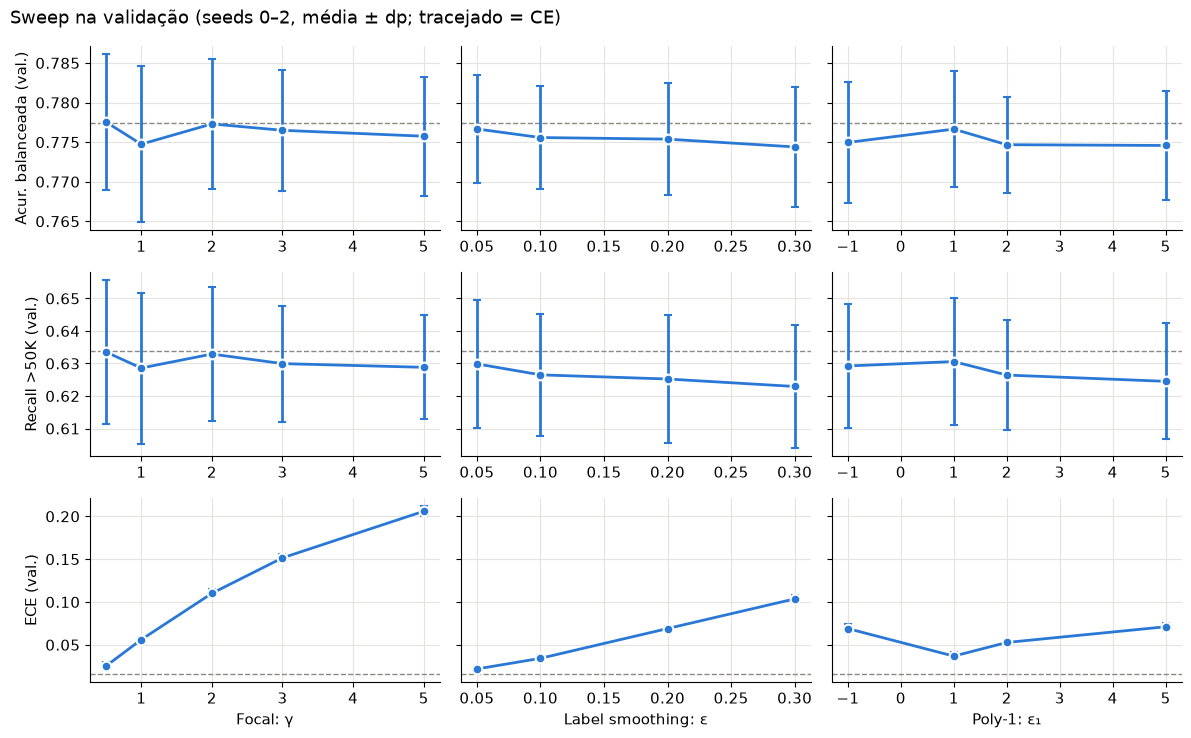

In [13]:
families = [
    ("focal", "Focal: γ"),
    ("ls", "Label smoothing: ε"),
    ("poly1", "Poly-1: ε₁")
]
metrics_to_plot = [
    ("balanced_accuracy", "Acur. balanceada (val.)"),
    ("minority_recall", "Recall >50K (val.)"),
    ("ece", "ECE (val.)")
]
ce_rows = [row for row in sweep if row["family"] == "ce"]

fig, axes = plt.subplots(3, 3, figsize=(12, 7.5), sharey="row")
for col, (family, x_label) in enumerate(families):
    params = sorted({row["param"] for row in sweep if row["family"] == family})
    for line, (metric, y_label) in enumerate(metrics_to_plot):
        ax = axes[line, col]
        stats = [mean_and_std([row["val"][metric] for row in sweep
                               if row["family"] == family and row["param"] == param])
                 for param in params]
        ax.axhline(np.mean([row["val"][metric] for row in ce_rows]), color=GRAY, ls="--", lw=1)
        ax.errorbar(params, [mean for mean, _ in stats], yerr=[std for _, std in stats],
                    color=BLUE, marker="o", ms=7, capsize=3, markeredgecolor="white",
                    markeredgewidth=1.5)
        if line == 2:
            ax.set_xlabel(x_label)
        if col == 0:
            ax.set_ylabel(y_label)
fig.suptitle("Sweep na validação (seeds 0–2, média ± dp; tracejado = CE)", x=0.01, ha="left")
fig.tight_layout()
fig.savefig(FIGURES / "fig3_sweep_validation.png")
plt.show()

**O que o sweep mostra.** Nenhum $\gamma$, $\varepsilon$ ou $\varepsilon_1$ passa da CE na
acurácia balanceada. As diferenças entre valores (milésimos) são menores que o desvio entre
seeds (≈ 0,008), então a "escolha" do melhor valor é em boa parte ruído: o que sai daqui é
o valor menos agressivo de cada família. O ECE, ao contrário, piora com clareza conforme o
hiperparâmetro cresce.



## 7. Etapa 2: runs finais no teste

Dez seeds (0–9) por configuração, medidas no `adult.test`:

- CE e CE ponderada;
- focal, label smoothing e Poly-1 com o valor escolhido na etapa 1;
- label smoothing com $\varepsilon \in \{0{,}1;\ 0{,}2;\ 0{,}3\}$ e focal com $\gamma = 2$, os valores usados nos artigos.

In [14]:
FINAL_SEEDS = tuple(range(10))
EXTRA_FINAL = [("ls", 0.1), ("ls", 0.2), ("ls", 0.3), ("focal", 2.0)]

configs = [("ce", None),
           ("wce", None),
           ("focal", selected["focal"]),
           ("ls", selected["ls"]),
           ("poly1", selected["poly1"])]

configs += [config for config in EXTRA_FINAL if config not in configs]

if USE_CACHE and (RESULTS / "final.json").exists():
    runs = json.loads((RESULTS / "final.json").read_text())["runs"]
    print(f"finais lidos de results/ ({len(runs)} runs)")
else:
    runs, start = [], time.time()
    for number, (family, param) in enumerate(configs, start=1):
        for seed in FINAL_SEEDS:
            runs.append(run_one(family, param, seed, final=True))
        print(f"[{number:2d}/{len(configs)}] {label(family, param):24s} {time.time() - start:5.0f} s")
    (RESULTS / "final.json").write_text(json.dumps({"selected": selected, "runs": runs}, indent=1))

[ 1/9] CE                         163 s
[ 2/9] Weighted CE                327 s
[ 3/9] Focal γ=0.5                477 s
[ 4/9] Label smoothing ε=0.05     626 s
[ 5/9] Poly-1 ε₁=1                776 s
[ 6/9] Label smoothing ε=0.1      923 s
[ 7/9] Label smoothing ε=0.2     1072 s
[ 8/9] Label smoothing ε=0.3     1247 s
[ 9/9] Focal γ=2                 1396 s


### O custo: FLOPs de treino por loss

O contador do engine soma tudo o que foi executado durante os 100 passos. Se a comparação é
mesmo a FLOPs iguais, as diferenças entre losses têm de ser desprezíveis.

In [15]:
MAIN = ["CE",
        "Weighted CE",
        label("focal", selected["focal"]),
        label("ls", selected["ls"]),
        label("poly1", selected["poly1"])
        ]

EXTRA = [name for name in dict.fromkeys(row["name"] for row in runs) if name not in MAIN]
THRESHOLD_ARM = "CE + limiar da validação"

def metric_values(name, metric, block="test"):
    """Os 10 valores de uma métrica, ordenados por seed (para o pareamento)."""
    if name == THRESHOLD_ARM:
        rows, block = [row for row in runs if row["name"] == "CE"], "test_at_val_threshold"
    else:
        rows = [row for row in runs if row["name"] == name]
    return np.array([row[block][metric] for row in sorted(rows, key=lambda row: row["seed"])])


def train_flops_of(name):
    return [row for row in runs if row["name"] == name][0]["train_flops"]


ce_flops = train_flops_of("CE")
lines = ["| Loss | FLOPs de treino | vs CE |", "|---|---|---|"]
for name in MAIN + EXTRA:
    flops = train_flops_of(name)
    lines.append(f"| {name} | {flops:,} | {100 * (flops / ce_flops - 1):+.3f} % |")
lines.append(f"| {THRESHOLD_ARM} | {ce_flops:,} | +0.000 % (a busca do limiar é NumPy, fora do grafo) |")
display(Markdown("\n".join(lines)))

| Loss | FLOPs de treino | vs CE |
|---|---|---|
| CE | 84,222,572,300 | +0.000 % |
| Weighted CE | 84,225,177,400 | +0.003 % |
| Focal γ=0.5 | 84,232,991,900 | +0.012 % |
| Label smoothing ε=0.05 | 84,225,177,200 | +0.003 % |
| Poly-1 ε₁=1 | 84,235,596,700 | +0.015 % |
| Label smoothing ε=0.1 | 84,225,177,200 | +0.003 % |
| Label smoothing ε=0.2 | 84,225,177,200 | +0.003 % |
| Label smoothing ε=0.3 | 84,225,177,200 | +0.003 % |
| Focal γ=2 | 84,232,991,900 | +0.012 % |
| CE + limiar da validação | 84,222,572,300 | +0.000 % (a busca do limiar é NumPy, fora do grafo) |

## 8. O que cada loss compra na classe minoritária

Primeiro a tabela completa, depois as diferenças **pareadas** contra a CE. Como a seed $k$ dá a
todas as losses a mesma divisão e a mesma inicialização, comparamos $\Delta_k =
\text{métrica}_k(\text{loss}) - \text{métrica}_k(\text{CE})$ em cada um dos 10 seeds e
contamos em quantos deles o $\Delta_k$ vai no mesmo sentido da média.

**A regra:** o efeito é considerado real quando o sinal se repete em **pelo menos 9 dos 10
seeds**. Se a loss não fizesse diferença nenhuma, cada seed seria como um cara ou coroa, e
tirar 9 ou mais resultados iguais em 10 por acaso acontece só em cerca de 2% das vezes.
Placares divididos (5/5, 6/4, 7/3) são ruído.

In [16]:
def mean_std_text(values, decimals=3):
    mean, std = mean_and_std(values)
    return f"{mean:.{decimals}f} ± {std:.{decimals}f}"


TEST_COLUMNS = [
    ("accuracy", "Acurácia"),
    ("minority_precision", "Precisão >50K"),
    ("minority_recall", "Recall >50K"),
    ("balanced_accuracy", "Acur. balanceada"),
    ("ece", "ECE")]

arms = MAIN + [THRESHOLD_ARM] + EXTRA
lines = ["| Loss | " + " | ".join(title for _, title in TEST_COLUMNS) + " |",
         "|---|" + "---|" * len(TEST_COLUMNS)]

for name in arms:
    lines.append(f"| {name} | " + " | ".join(mean_std_text(metric_values(name, metric))
                                             for metric, _ in TEST_COLUMNS) + " |")
display(Markdown("**Teste, limiar 0,5, 10 seeds (média ± dp)**\n\n" + "\n".join(lines)))

PAIRED_COLUMNS = TEST_COLUMNS
lines = ["| Loss | " + " | ".join(title for _, title in PAIRED_COLUMNS) + " |",
         "|---|" + "---|" * len(PAIRED_COLUMNS)]
for name in arms[1:]:
    cells = []
    for metric, _ in PAIRED_COLUMNS:
        delta = metric_values(name, metric) - metric_values("CE", metric)
        if np.all(delta == 0):
            cells.append("idêntico")
            continue
        mean = delta.mean()
        agreeing = int(np.sum(np.sign(delta) == np.sign(mean)))   # seeds no mesmo sentido da média
        cells.append(f"{mean:+.4f} ({agreeing}/{len(delta)}){' *' if agreeing >= 9 else ''}")
    lines.append(f"| {name} | " + " | ".join(cells) + " |")
display(Markdown("**Δ pareado contra a CE**: média do Δ_k e em quantos seeds ele vai no mesmo "
                 "sentido (`*` = pelo menos 9 de 10)\n\n" + "\n".join(lines)))

**Teste, limiar 0,5, 10 seeds (média ± dp)**

| Loss | Acurácia | Precisão >50K | Recall >50K | Acur. balanceada | ECE |
|---|---|---|---|---|---|
| CE | 0.855 ± 0.001 | 0.724 ± 0.005 | 0.626 ± 0.004 | 0.776 ± 0.002 | 0.013 ± 0.002 |
| Weighted CE | 0.814 ± 0.002 | 0.572 ± 0.004 | 0.836 ± 0.007 | 0.821 ± 0.002 | 0.042 ± 0.003 |
| Focal γ=0.5 | 0.855 ± 0.001 | 0.724 ± 0.004 | 0.626 ± 0.005 | 0.776 ± 0.002 | 0.025 ± 0.002 |
| Label smoothing ε=0.05 | 0.857 ± 0.001 | 0.731 ± 0.006 | 0.623 ± 0.005 | 0.776 ± 0.002 | 0.018 ± 0.001 |
| Poly-1 ε₁=1 | 0.856 ± 0.001 | 0.729 ± 0.004 | 0.624 ± 0.005 | 0.776 ± 0.002 | 0.036 ± 0.001 |
| CE + limiar da validação | 0.808 ± 0.010 | 0.563 ± 0.017 | 0.850 ± 0.020 | 0.823 ± 0.001 | 0.013 ± 0.002 |
| Label smoothing ε=0.1 | 0.857 ± 0.001 | 0.732 ± 0.005 | 0.623 ± 0.006 | 0.776 ± 0.002 | 0.033 ± 0.002 |
| Label smoothing ε=0.2 | 0.857 ± 0.001 | 0.734 ± 0.006 | 0.619 ± 0.007 | 0.775 ± 0.003 | 0.069 ± 0.002 |
| Label smoothing ε=0.3 | 0.857 ± 0.001 | 0.735 ± 0.005 | 0.619 ± 0.006 | 0.775 ± 0.002 | 0.107 ± 0.002 |
| Focal γ=2 | 0.855 ± 0.002 | 0.724 ± 0.005 | 0.625 ± 0.006 | 0.776 ± 0.003 | 0.111 ± 0.005 |

**Δ pareado contra a CE**: média do Δ_k e em quantos seeds ele vai no mesmo sentido (`*` = pelo menos 9 de 10)

| Loss | Acurácia | Precisão >50K | Recall >50K | Acur. balanceada | ECE |
|---|---|---|---|---|---|
| Weighted CE | -0.0419 (10/10) * | -0.1523 (10/10) * | +0.2094 (10/10) * | +0.0449 (10/10) * | +0.0297 (10/10) * |
| Focal γ=0.5 | -0.0002 (6/10) | -0.0005 (6/10) | -0.0001 (6/10) | -0.0001 (4/10) | +0.0124 (10/10) * |
| Label smoothing ε=0.05 | +0.0012 (10/10) * | +0.0061 (10/10) * | -0.0036 (8/10) | -0.0005 (5/10) | +0.0050 (10/10) * |
| Poly-1 ε₁=1 | +0.0009 (10/10) * | +0.0044 (10/10) * | -0.0024 (7/10) | -0.0003 (6/10) | +0.0234 (10/10) * |
| CE + limiar da validação | -0.0470 (10/10) * | -0.1610 (10/10) * | +0.2236 (10/10) * | +0.0465 (10/10) * | idêntico |
| Label smoothing ε=0.1 | +0.0015 (9/10) * | +0.0074 (10/10) * | -0.0038 (7/10) | -0.0003 (5/10) | +0.0208 (10/10) * |
| Label smoothing ε=0.2 | +0.0017 (9/10) * | +0.0099 (10/10) * | -0.0069 (9/10) * | -0.0013 (6/10) | +0.0568 (10/10) * |
| Label smoothing ε=0.3 | +0.0020 (10/10) * | +0.0111 (10/10) * | -0.0072 (9/10) * | -0.0012 (7/10) | +0.0941 (10/10) * |
| Focal γ=2 | -0.0004 (5/10) | -0.0008 (5/10) | -0.0009 (6/10) | -0.0006 (5/10) | +0.0987 (10/10) * |

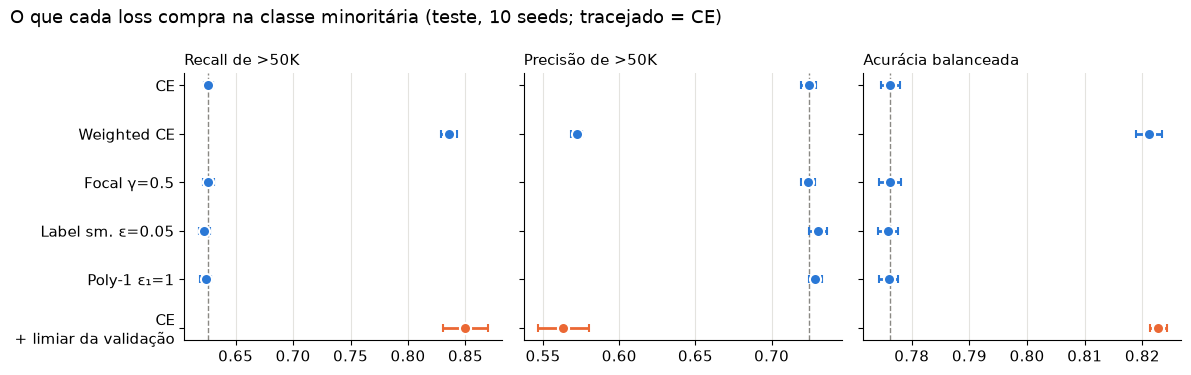

In [17]:
arms = MAIN + [THRESHOLD_ARM]
panels = [("minority_recall", "Recall de >50K"), ("minority_precision", "Precisão de >50K"),
          ("balanced_accuracy", "Acurácia balanceada")]


def short_name(name):
    return name.replace("Label smoothing", "Label sm.").replace(" + limiar", "\n+ limiar")


fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True)
y_positions = np.arange(len(arms))[::-1]
for ax, (metric, title) in zip(axes, panels):
    ax.axvline(metric_values("CE", metric).mean(), color=GRAY, lw=1, ls="--")
    for y_position, name in zip(y_positions, arms):
        mean, std = mean_and_std(metric_values(name, metric))
        color = ORANGE if name == THRESHOLD_ARM else BLUE
        ax.errorbar(mean, y_position, xerr=std, fmt="o", ms=8, color=color, capsize=3,
                    markeredgecolor="white", markeredgewidth=1.5)
    ax.set_title(title, loc="left", fontsize=11)
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(y_positions, [short_name(name) for name in arms])
fig.suptitle("O que cada loss compra na classe minoritária (teste, 10 seeds; tracejado = CE)",
             x=0.01, ha="left")
fig.tight_layout()
fig.savefig(FIGURES / "fig1_minority_metrics.png")
plt.show()

## 9. Calibração

Os diagramas abaixo juntam as 15 faixas das 10 seeds. Abaixo da diagonal o modelo promete
mais do que acerta (superconfiante); acima, promete menos (subconfiante).

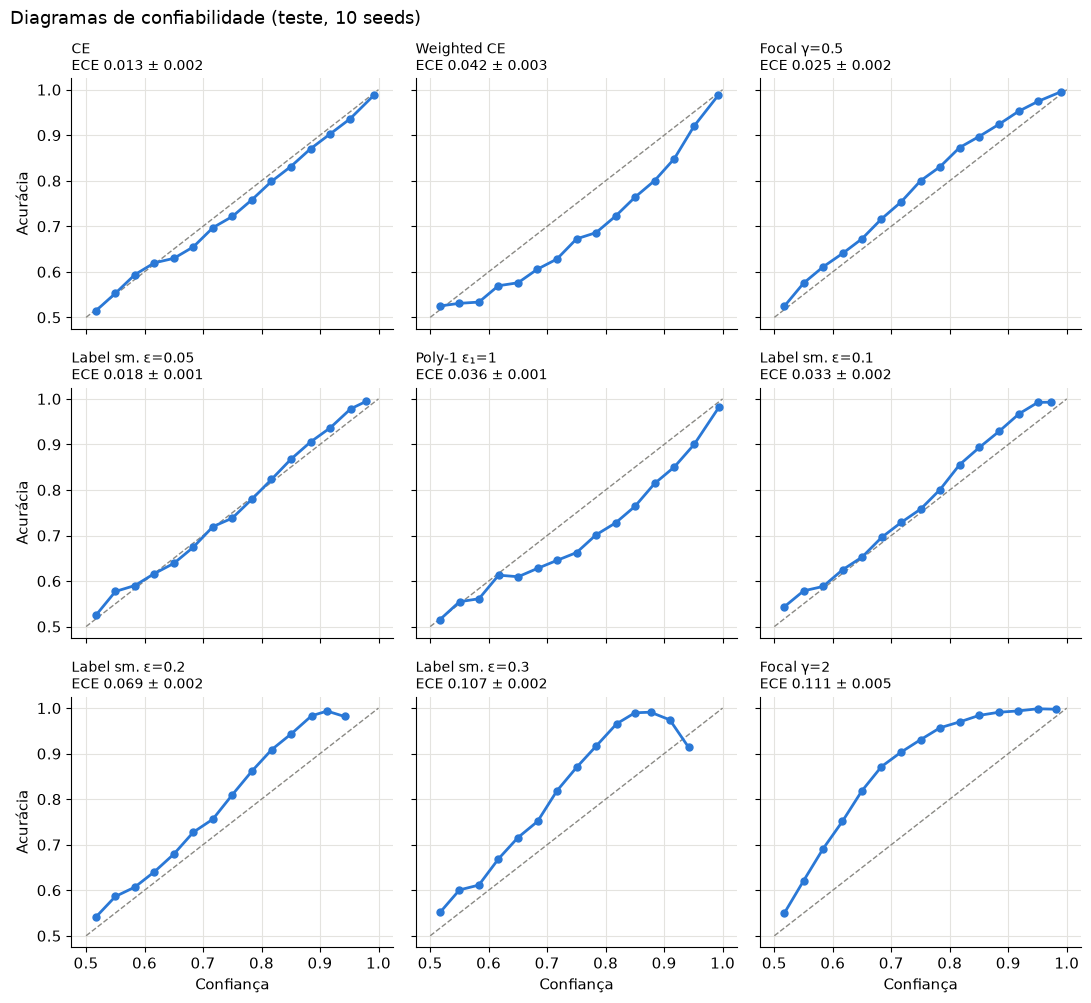

In [18]:
arms = MAIN + [name for name in EXTRA if name.startswith(("Label", "Focal"))]
n_rows = int(np.ceil(len(arms) / 3))
fig, axes = plt.subplots(n_rows, 3, figsize=(11, 3.4 * n_rows), sharex=True, sharey=True)
for ax, name in zip(axes.flat, arms):
    rows = [row for row in runs if row["name"] == name]
    count = np.array([row["reliability"]["count"] for row in rows], dtype=float)
    confidence = np.nan_to_num(np.array([row["reliability"]["confidence"] for row in rows], dtype=float))
    accuracy = np.nan_to_num(np.array([row["reliability"]["accuracy"] for row in rows], dtype=float))
    total = count.sum(axis=0)
    enough = total > 50                                    # esconde faixas quase vazias
    pooled_confidence = (confidence * count).sum(axis=0)[enough] / total[enough]
    pooled_accuracy = (accuracy * count).sum(axis=0)[enough] / total[enough]
    ax.plot([0.5, 1], [0.5, 1], color=GRAY, lw=1, ls="--")
    ax.plot(pooled_confidence, pooled_accuracy, color=BLUE, marker="o", ms=5)
    ax.set_title(f"{short_name(name)}\nECE {mean_std_text(metric_values(name, 'ece'))}",
                 loc="left", fontsize=10)
for ax in axes.flat[len(arms):]:
    ax.set_visible(False)
for ax in axes[-1]:
    ax.set_xlabel("Confiança")
for ax in axes[:, 0]:
    ax.set_ylabel("Acurácia")
fig.suptitle("Diagramas de confiabilidade (teste, 10 seeds)", x=0.01, ha="left")
fig.tight_layout()
fig.savefig(FIGURES / "fig4_reliability.png")
plt.show()

## 10. A geometria da penúltima camada

Primeiro a figura no estilo da Fig. 1 de Müller et al.
(seed 0), em unidades da distância entre os centros das classes, para que losses com escalas
diferentes fiquem comparáveis.

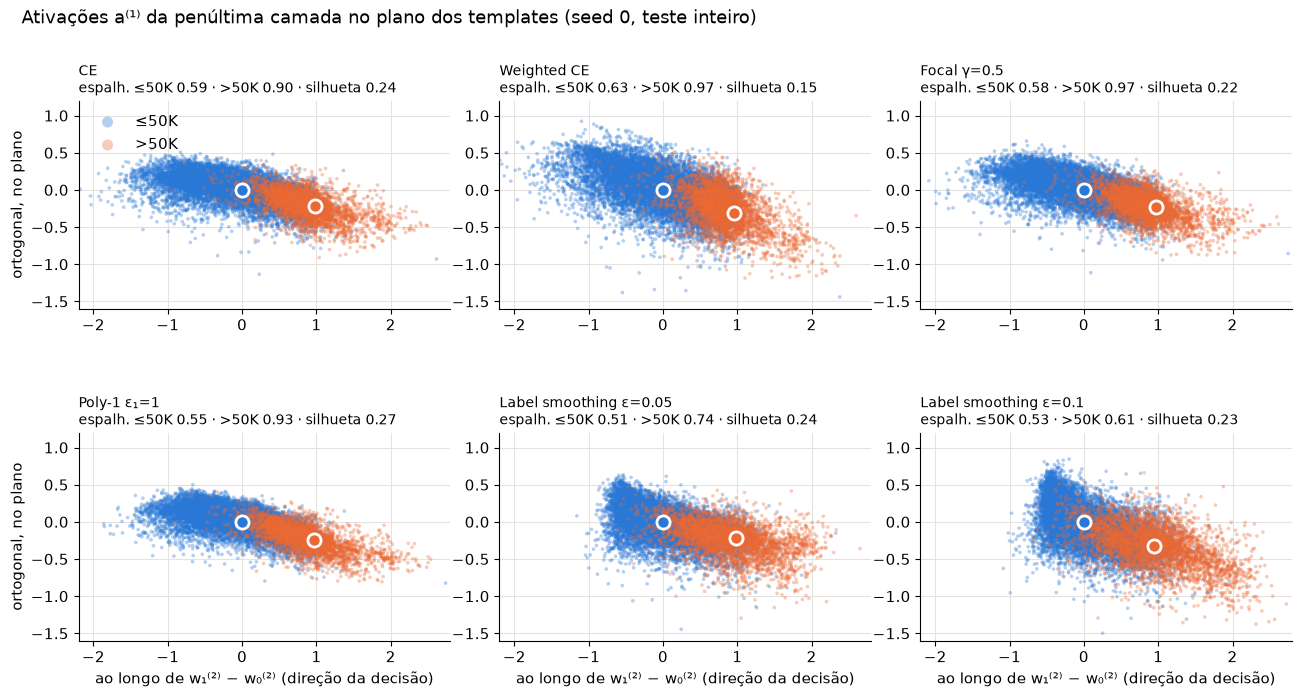

In [24]:
shown = [
    ("ce", None),
    ("wce", None),
    ("focal", selected["focal"]),
    ("poly1", selected["poly1"]),
    ("ls", 0.05), ("ls", 0.1)]

fig, axes = plt.subplots(2, 3, figsize=(13, 7.2))
for ax, (family, param) in zip(axes.flat, shown):
    saved = np.load(RESULTS / f"proj_{family}_{param}.npz")
    plane, labels = saved["plane"], saved["labels"]
    # unidades da distância entre os centros, com o centro <=50K na origem
    center_majority, center_minority = plane[labels == 0].mean(0), plane[labels == 1].mean(0)
    scaled = (plane - center_majority) / np.linalg.norm(center_minority - center_majority)
    for c, color, class_name in ((0, BLUE, "≤50K"), (1, ORANGE, ">50K")):
        ax.scatter(scaled[labels == c, 0], scaled[labels == c, 1], s=7, color=color, alpha=0.35,
                   edgecolor="none", label=class_name, rasterized=True)
        ax.scatter(*scaled[labels == c].mean(0), s=90, color=color, edgecolor="white",
                   linewidth=2, zorder=5)
    seed0 = [row for row in runs if row["family"] == family and row["param"] == param
             and row["seed"] == 0][0]["geometry"]
    ax.set_title(f"{label(family, param)}\nespalh. ≤50K {seed0['spread_majority']:.2f} · "
                 f">50K {seed0['spread_minority']:.2f} · silhueta {seed0['silhouette']:.2f}",
                 loc="left", fontsize=10)
    ax.set_xlim(-2.2, 2.8); ax.set_ylim(-1.6, 1.2); ax.set_aspect("equal")
axes[0, 0].legend(loc="upper left", frameon=False, markerscale=3)
for ax in axes[-1]:
    ax.set_xlabel("ao longo de w₁⁽²⁾ − w₀⁽²⁾ (direção da decisão)")
for ax in axes[:, 0]:
    ax.set_ylabel("ortogonal, no plano")
fig.suptitle("Ativações a⁽¹⁾ da penúltima camada no plano dos templates (seed 0, teste inteiro)",
             x=0.01, ha="left")
fig.tight_layout(h_pad=2.5)
fig.savefig(FIGURES / "fig5_template_projection.png")
plt.show()

In [25]:
GEOMETRY_COLUMNS = [("silhouette", "silhouette_score (cosseno, 64-d)"),
                    ("spread_majority", "Espalh. ≤50K"), ("spread_minority", "Espalh. >50K")]
lines = ["| Loss | " + " | ".join(title for _, title in GEOMETRY_COLUMNS) + " |",
         "|---|" + "---|" * len(GEOMETRY_COLUMNS)]
for name in MAIN + EXTRA:
    lines.append(f"| {name} | " + " | ".join(mean_std_text(metric_values(name, metric, "geometry"))
                                             for metric, _ in GEOMETRY_COLUMNS) + " |")
display(Markdown("**Geometria, 10 seeds (média ± dp)**\n\n" + "\n".join(lines)))

**Geometria, 10 seeds (média ± dp)**

| Loss | silhouette_score (cosseno, 64-d) | Espalh. ≤50K | Espalh. >50K |
|---|---|---|---|
| CE | 0.245 ± 0.020 | 0.618 ± 0.029 | 0.913 ± 0.076 |
| Weighted CE | 0.157 ± 0.025 | 0.654 ± 0.037 | 0.920 ± 0.078 |
| Focal γ=0.5 | 0.227 ± 0.024 | 0.616 ± 0.031 | 0.955 ± 0.061 |
| Label smoothing ε=0.05 | 0.247 ± 0.018 | 0.520 ± 0.036 | 0.770 ± 0.092 |
| Poly-1 ε₁=1 | 0.267 ± 0.016 | 0.571 ± 0.024 | 0.941 ± 0.080 |
| Label smoothing ε=0.1 | 0.238 ± 0.022 | 0.527 ± 0.040 | 0.661 ± 0.040 |
| Label smoothing ε=0.2 | 0.228 ± 0.021 | 0.511 ± 0.035 | 0.674 ± 0.049 |
| Label smoothing ε=0.3 | 0.218 ± 0.022 | 0.512 ± 0.031 | 0.697 ± 0.054 |
| Focal γ=2 | 0.196 ± 0.027 | 0.640 ± 0.032 | 0.979 ± 0.073 |

### Dose-resposta do label smoothing

Se o smoothing aperta os clusters, o efeito deve crescer com $\varepsilon$. E se apertar os
clusters fosse o que ajuda o classificador, recall e acurácia balanceada deveriam crescer junto. A figura põe
as duas coisas lado a lado: geometria em azul, desempenho em laranja.

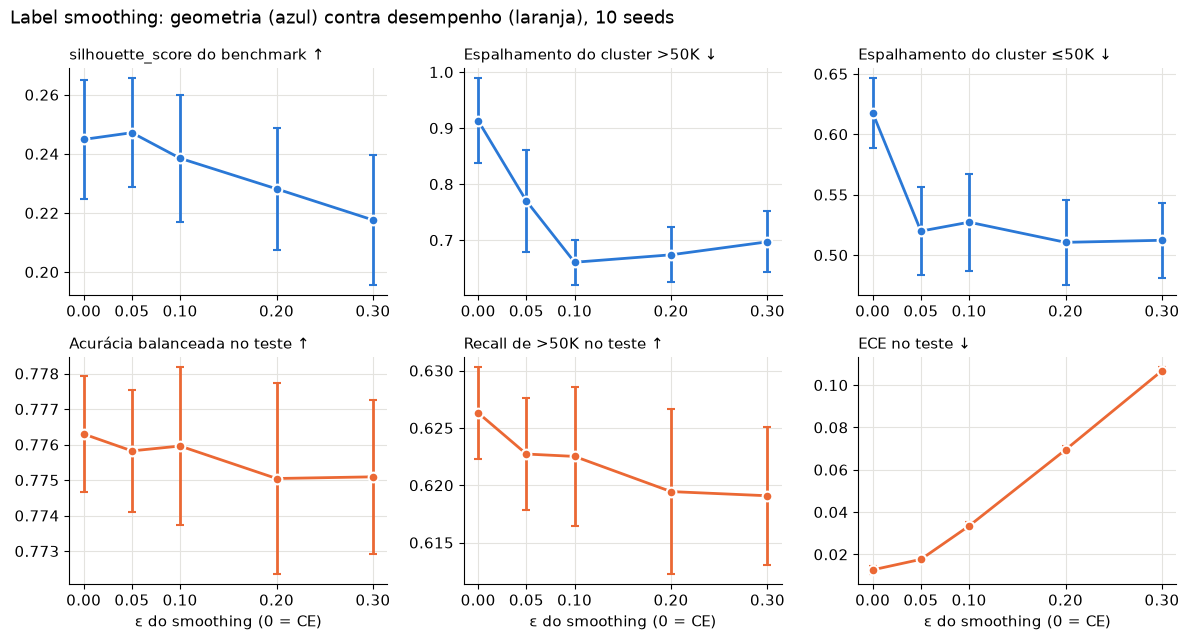

In [26]:
epsilons = [0.0] + sorted({row["param"] for row in runs if row["family"] == "ls"})


def name_for(epsilon):
    return "CE" if epsilon == 0 else label("ls", epsilon)


panels = [("geometry", "silhouette", "silhouette_score do benchmark ↑"),
          ("geometry", "spread_minority", "Espalhamento do cluster >50K ↓"),
          ("geometry", "spread_majority", "Espalhamento do cluster ≤50K ↓"),
          ("test", "balanced_accuracy", "Acurácia balanceada no teste ↑"),
          ("test", "minority_recall", "Recall de >50K no teste ↑"),
          ("test", "ece", "ECE no teste ↓")]
fig, axes = plt.subplots(2, 3, figsize=(12, 6.5))
for ax, (block, metric, title) in zip(axes.flat, panels):
    stats = [mean_and_std(metric_values(name_for(epsilon), metric, block)) for epsilon in epsilons]
    ax.errorbar(epsilons, [mean for mean, _ in stats], yerr=[std for _, std in stats],
                color=BLUE if block == "geometry" else ORANGE, marker="o", ms=7, capsize=3,
                markeredgecolor="white", markeredgewidth=1.5)
    ax.set_title(title, loc="left", fontsize=11)
    ax.set_xticks(epsilons)
for ax in axes[-1]:
    ax.set_xlabel("ε do smoothing (0 = CE)")
fig.suptitle("Label smoothing: geometria (azul) contra desempenho (laranja), 10 seeds", x=0.01, ha="left")
fig.tight_layout()
fig.savefig(FIGURES / "fig6_ls_dose_response.png")
plt.show()

## 11. Resposta

**Qual loss compra mais na classe minoritária a FLOPs iguais?** A CE ponderada, e só ela, mas
o que ela compra é um deslocamento do limiar de decisão. Ajustar o limiar da CE na validação
faz o mesmo de graça e mantém a calibração. Focal, label smoothing e Poly-1 não compram nada
mensurável. Todas custam o mesmo: 84,22 GFLOP de treino, com diferença máxima de +0,015 %.

**Muda a geometria como Müller et al. afirmam?** Em parte, e depende da régua. No plano dos
templates, o espalhamento de cada classe cai com o label smoothing como no artigo. Com o `silhouette_score`
do benchmark (cosseno, 64-d), que é a medida pedida
pela questão, a silhueta *cai*: o aperto é de tamanho, não de direção. Nos dois
casos o aperto não melhora a separação que o classificador usa e vem com recall de `>50K` menor e
calibração pior.

**Acurácia contra calibração.** A questão lembra que o smoothing costuma trocar acurácia por
calibração. Aqui a troca aparece ao contrário: o smoothing ganha um pouco de acurácia simples
(+0,0015 a +0,0020 com $\varepsilon \ge 0{,}1$, em 9 ou 10 de 10 seeds), ganho que vem da
classe majoritária, e perde calibração (ECE de 0,013 para até 0,107).

### Resumo dos resultados

| Afirmação | Resultado | Evidência |
|---|---|---|
| nenhuma loss de formato melhora a acurácia balanceada de forma consistente | **confirmada** | \|Δ\| ≤ 0,0013 e no máximo 7 de 10 seeds no mesmo sentido, em todas as losses de formato |
| a CE ponderada equivale a deslocar o limiar | **confirmada** | CE + limiar 0,823 ± 0,002 contra CE ponderada 0,821 ± 0,002 |
| o smoothing sobe a silhueta e aperta os clusters | **parcial** | espalhamento no plano dos templates: cai; `silhouette_score` cosseno: não sobe, cai (em 10 de 10 seeds com ε = 0,3) |
| o aperto não melhora a classe minoritária | **confirmada** | recall de `>50K` cai de 0,626 para 0,619 com ε = 0,3 (9 de 10 seeds); acurácia balanceada dentro do ruído |

**Próximos passos baratos:** focal com $\alpha$; um alvo com 3 ou mais classes para testar a
equidistância; um modelo mais largo ou treinado por mais tempo, onde a CE fique
superconfiante.

## 12. Reprodução

- **Comando:** abra este notebook e rode as células de cima para baixo com `USE_CACHE = False`.
- **Seeds:** 0, 1 e 2 no sweep; 0 a 9 nos runs finais; amostra da geometria fixa pela seed
  12345 do `default_rng`.
- **Dependências:** só o repositório (`bert_cpu`, `datasets`, `research/benchmark.py`), NumPy
  e matplotlib para as figuras.
- **Saídas:** `results/sweep.json`, `results/final.json`, `results/proj_*.npz` e
  `figures/*.png`.

A célula abaixo mede o custo de relógio do estudo inteiro nesta execução.

In [22]:
n_trained = len(sweep) + len(runs)
print(f"{n_trained} treinos ({len(sweep)} no sweep, {len(runs)} finais) + 1 baseline")
print(f"tempo total do notebook: {(time.time() - START_TIME) / 60:.1f} min")
print(f"FLOPs de treino somados: {sum(row['train_flops'] for row in sweep + runs) / 1e12:.2f} TFLOP")

135 treinos (45 no sweep, 90 finais) + 1 baseline
tempo total do notebook: 30.8 min
FLOPs de treino somados: 11.37 TFLOP
